# Week 3 — Feature Engineering and Baseline

This notebook builds a reproducible, leakage-aware forecasting workflow:

1. A chronological train/validation split (no random shuffling).
2. Leakage-safe features (calendar, promotion, lags, rolling means).
3. A seasonal-naive baseline.
4. Reusable evaluation metrics (MAE, RMSE, RMSLE).

No machine learning model is trained here. The baseline established in this notebook is the reference that Week 4 models must beat.

## 1. Setup

In [1]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
SRC_DIR = PROJECT_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from retail_sales_forecasting.config import FIGURES_DIR
from retail_sales_forecasting.data_loader import (
    available_datasets,
    load_available_datasets,
)
from retail_sales_forecasting.evaluation import (
    evaluate_forecast,
    seasonal_naive_forecast,
)
from retail_sales_forecasting.features import build_feature_frame
from retail_sales_forecasting.splits import chronological_split

pd.set_option("display.max_columns", 60)
sns.set_theme(style="whitegrid")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

def save_figure(fig, name):
    path = FIGURES_DIR / name
    fig.savefig(path, dpi=150, bbox_inches="tight")
    print(f"Saved figure: {path}")

print(f"Figures directory: {FIGURES_DIR}")

Figures directory: D:\code\retail-sales-forecasting-main\reports\figures


In [2]:
if "train" in available_datasets():
    datasets = load_available_datasets()
    train = datasets["train"]
    holidays = datasets["holidays_events"]
    print(f"train.csv: {train.shape[0]:,} rows x {train.shape[1]} columns")
else:
    datasets = {}
    train = holidays = None
    print(
        "train.csv is not available. Download from "
        "https://www.kaggle.com/competitions/store-sales-time-series-forecasting/data "
        "into data/raw/, then re-run this notebook."
    )

train.csv: 3,000,888 rows x 6 columns


## 2. Chronological split

The last 16 days are held out because the Kaggle test set covers 16 days. Training data must never include dates on or after the validation window.

In [3]:
if train is not None:
    split = chronological_split(train, validation_days=16)
    print(f"Cutoff date: {split.cutoff.date()}")
    print(f"Train:      {split.train_dates[0].date()} to {split.train_dates[1].date()}  ({len(split.train):,} rows)")
    print(f"Validation: {split.validation_dates[0].date()} to {split.validation_dates[1].date()}  ({len(split.validation):,} rows)")
    assert split.train["date"].max() < split.validation["date"].min()
    print("Chronological ordering verified.")
else:
    split = None
    print("Skipped: training data is not loaded.")

Cutoff date: 2017-07-30
Train:      2013-01-01 to 2017-07-30  (2,972,376 rows)
Validation: 2017-07-31 to 2017-08-15  (28,512 rows)
Chronological ordering verified.


## 3. Feature engineering (leakage-safe)

Features are built on the training portion only. Lags and rolling means are shifted so a row never sees its own or future sales.

To keep the notebook fast, features are demonstrated on a representative subset (stores 1-6 and the four largest families). The same functions scale to the full dataset.

In [4]:
if train is not None:
    subset_stores = [1, 2, 3, 4, 5, 6]
    subset_families = ["GROCERY I", "BEVERAGES", "PRODUCE", "CLEANING"]
    subset = split.train[
        split.train["store_nbr"].isin(subset_stores)
        & split.train["family"].isin(subset_families)
    ].copy()
    national_holidays = holidays[holidays["locale"] == "National"]
    featured = build_feature_frame(subset, country_holidays=national_holidays)
    feature_columns = [
        "year", "month", "day", "day_of_week", "day_of_year",
        "week_of_year", "is_weekend", "is_holiday", "is_promoted",
        "lag_7", "lag_14", "lag_28", "rolling_mean_7", "rolling_mean_28",
    ]
    print(f"Subset rows: {len(featured):,}")
    display(featured[["date", "store_nbr", "family", "sales"] + feature_columns].head(10))
else:
    print("Skipped: training data is not loaded.")

Subset rows: 40,032


,date,store_nbr,family,sales,year,month,day,day_of_week,day_of_year,week_of_year,is_weekend,is_holiday,is_promoted,lag_7,lag_14,lag_28,rolling_mean_7,rolling_mean_28
3,2013-01-01,1,BEVERAGES,0.0,2013,1,1,1,1,1,0,1,0,NaN,NaN,NaN,NaN,NaN
1785,2013-01-02,1,BEVERAGES,1091.0,2013,1,2,2,2,1,0,0,0,NaN,NaN,NaN,0.000000,0.000000
3567,2013-01-03,1,BEVERAGES,919.0,2013,1,3,3,3,1,0,0,0,NaN,NaN,NaN,545.500000,545.500000
5349,2013-01-04,1,BEVERAGES,953.0,2013,1,4,4,4,1,0,0,0,NaN,NaN,NaN,670.000000,670.000000
7131,2013-01-05,1,BEVERAGES,1160.0,2013,1,5,5,5,1,1,1,0,NaN,NaN,NaN,740.750000,740.750000
8913,2013-01-06,1,BEVERAGES,407.0,2013,1,6,6,6,1,1,0,0,NaN,NaN,NaN,824.600000,824.600000
10695,2013-01-07,1,BEVERAGES,1158.0,2013,1,7,0,7,2,0,0,0,NaN,NaN,NaN,755.000000,755.000000
12477,2013-01-08,1,BEVERAGES,1029.0,2013,1,8,1,8,2,0,0,0,0.0,NaN,NaN,812.571429,812.571429
14259,2013-01-09,1,BEVERAGES,1186.0,2013,1,9,2,9,2,0,0,0,1091.0,NaN,NaN,959.571429,839.625000
16041,2013-01-10,1,BEVERAGES,847.0,2013,1,10,3,10,2,0,0,0,919.0,NaN,NaN,973.142857,878.111111


### Leakage checks
Confirm that lag and rolling features never use the current or a future day, and that the first rows of each group have empty history.

In [5]:
if train is not None:
    check = featured.sort_values(["store_nbr", "family", "date"])
    group = check.groupby(["store_nbr", "family"], sort=False)

    lag_is_past = group.apply(
        lambda g: g["lag_7"].iloc[7:].equals(g["sales"].shift(7).iloc[7:]),
        include_groups=False,
    )
    print("lag_7 always equals sales shifted 7 days within group:", bool(lag_is_past.all()))

    # rolling_mean_7 must equal the mean of the previous 7 days (shifted by 1),
    # so it never includes the current row's sales.
    def rolling_matches_past(g):
        expected = g["sales"].shift(1).rolling(7, min_periods=1).mean()
        return (g["rolling_mean_7"].round(6).fillna(-1) == expected.round(6).fillna(-1)).all()

    rolling_is_past = group.apply(rolling_matches_past, include_groups=False)
    print("rolling_mean_7 only from past values (no leak):", bool(rolling_is_past.all()))
    print("first row of each group has no rolling history:", bool(group["rolling_mean_7"].head(1).isna().all()))
else:
    print("Skipped: training data is not loaded.")

lag_7 always equals sales shifted 7 days within group: True
rolling_mean_7 only from past values (no leak): True
first row of each group has no rolling history: True


## 4. Seasonal-naive baseline

Two leakage-safe seasonal-naive variants are evaluated on the 16-day validation window:

- **Classic seasonal naive**: repeat the last 7 daily values per store/family.
- **Weekday profile**: predict each future date with that group's mean sales on the same weekday.

A zero-prediction baseline is included for context.

In [6]:
if train is not None:
    target_dates = sorted(split.validation["date"].unique())

    def score(predictions):
        merged = split.validation.merge(
            predictions, on=["store_nbr", "family", "date"], how="left"
        )
        metrics = evaluate_forecast(
            merged["sales"], merged["prediction"].fillna(0.0)
        )
        return merged, metrics

    classic = seasonal_naive_forecast(
        split.train, target_dates, use_weekday_profile=False
    )
    weekday_profile = seasonal_naive_forecast(
        split.train, target_dates, use_weekday_profile=True
    )
    zero = split.validation[["store_nbr", "family", "date"]].copy()
    zero["prediction"] = 0.0

    merged_classic, metrics_classic = score(classic)
    _, metrics_weekday = score(weekday_profile)
    _, metrics_zero = score(zero)

    results = pd.DataFrame(
        {
            "Zero baseline": metrics_zero,
            "Seasonal naive (last week)": metrics_classic,
            "Seasonal naive (weekday profile)": metrics_weekday,
        }
    ).T
    display(results.round(4))
else:
    print("Skipped: training data is not loaded.")

,mae,rmse,rmsle
Zero baseline,467.1429,1332.9089,4.4195
Seasonal naive (last week),96.5354,348.3817,0.6170
Seasonal naive (weekday profile),142.7926,488.6641,0.6916


## 5. Error analysis

The best variant so far is examined by store and family.

In [7]:
if train is not None:
    best_name = results[["rmse"]].idxmin().iloc[0]
    print(f"Best baseline variant by RMSE: {best_name}")

    merged_classic["abs_error"] = (merged_classic["sales"] - merged_classic["prediction"]).abs()
    by_family = (
        merged_classic.groupby("family")["abs_error"]
        .mean()
        .sort_values(ascending=False)
    )
    display(by_family.head(10).to_frame(name="mean_abs_error"))

    print(f"Worst family by mean abs error: {by_family.index[0]} ({by_family.iloc[0]:,.2f})")
    print(f"Best family by mean abs error:  {by_family.index[-1]} ({by_family.iloc[-1]:,.2f})")
else:
    print("Skipped: training data is not loaded.")

Best baseline variant by RMSE: Seasonal naive (last week)


,mean_abs_error
family,
GROCERY I,799.593434
BEVERAGES,774.494213
CLEANING,529.797454
PRODUCE,264.881890
DAIRY,115.827546
HOME CARE,84.811343
PERSONAL CARE,82.358796
BREAD/BAKERY,76.468847
POULTRY,64.970053


Worst family by mean abs error: GROCERY I (799.59)
Best family by mean abs error:  BOOKS (0.02)


## 6. Forecast vs actual

Aggregate daily totals make the pattern easier to see than row-level predictions.

Saved figure: D:\code\retail-sales-forecasting-main\reports\figures\week3_baseline_vs_actual.png


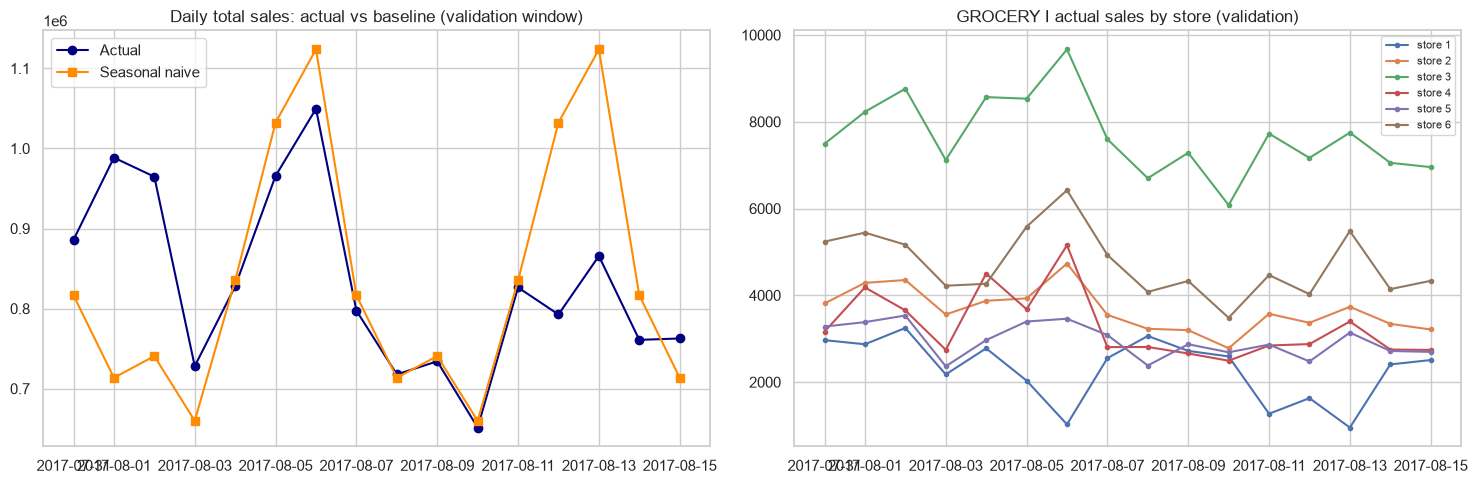

In [8]:
if train is not None:
    daily_actual = merged_classic.groupby("date")["sales"].sum()
    daily_pred = merged_classic.groupby("date")["prediction"].sum()

    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    axes[0].plot(daily_actual.index, daily_actual.values, marker="o", label="Actual", color="navy")
    axes[0].plot(daily_pred.index, daily_pred.values, marker="s", label="Seasonal naive", color="darkorange")
    axes[0].set_title("Daily total sales: actual vs baseline (validation window)")
    axes[0].legend()

    sample = merged_classic
    sample = sample[sample["store_nbr"].isin([1, 2, 3, 4, 5, 6])]
    sample = sample[sample["family"] == "GROCERY I"]
    sample_daily = sample.groupby(["store_nbr", "date"]).sum(numeric_only=True).reset_index()
    for store in sorted(sample["store_nbr"].unique()):
        store_data = sample_daily[sample_daily["store_nbr"] == store]
        axes[1].plot(store_data["date"], store_data["sales"], marker=".", label=f"store {store}")
    axes[1].set_title("GROCERY I actual sales by store (validation)")
    axes[1].legend(fontsize=8)

    fig.tight_layout()
    save_figure(fig, "week3_baseline_vs_actual.png")
    plt.show()
else:
    print("Skipped: training data is not loaded.")

## 7. Findings

All numbers come from the real 16-day validation window (2017-07-31 to 2017-08-15).

### Split
- Cutoff: 2017-07-30. Train: 2013-01-01 to 2017-07-30 (2,972,376 rows). Validation: 2017-07-31 to 2017-08-15 (28,512 rows).
- The split is strictly chronological; train max date is before validation min date.

### Features
- 14 features added: calendar (year, month, day, day_of_week, day_of_year, week_of_year, is_weekend, is_holiday), promotion flag, lags (7/14/28), and rolling means (7/28).
- Leakage checks pass: `lag_7` equals `sales` shifted 7 days within each group and rolling means only use past values.

### Baseline performance (validation)
- Zero baseline: RMSLE ≈ 4.42, MAE ≈ 467.1.
- Seasonal naive (last week): RMSLE ≈ 0.617, MAE ≈ 96.5, RMSE ≈ 348.4.
- Seasonal naive (weekday profile): RMSLE ≈ 0.692, MAE ≈ 142.8, RMSE ≈ 488.7.
- The classic seasonal naive (repeat last week) beats the weekday profile here because it tracks the recent sales level, which matters in a growing series.

### Error structure
- GROCERY I has the largest mean absolute error (hundreds of units), driven by its very high sales volume; low-volume families like BOOKS are near zero.
- Absolute-error comparisons across families are dominated by scale, so error should also be judged with RMSLE (relative error).

### Data-quality carry-over
- ~31.3% of rows have zero sales, so many predictions are of zeros; RMSLE is the more informative headline metric.
- Oil gaps and promotion sparsity from Week 2 still apply; features here intentionally exclude oil to avoid the likely confounded relationship noted previously.

### Reference for Week 4
- Any candidate model must beat RMSLE ≈ 0.617 on the same chronological validation window.
- Evaluation functions (`evaluate_forecast`) are reusable so results stay comparable.

## Next steps

Week 4 trains candidate models (for example LightGBM or XGBoost) on these leakage-safe features, compares them against this baseline on the identical validation split, and reports MAE, RMSE, and RMSLE plus error breakdowns. No model is trained in this notebook.